In [ ]:
# Figure 1: (b) and (c)
# Figure 1: (a) give as input as generated from ArcMap

Plot successfully saved to:
  - C:\Users\PC1\Desktop\Code_Data\Data\Figure_1\output\Figure_1.png


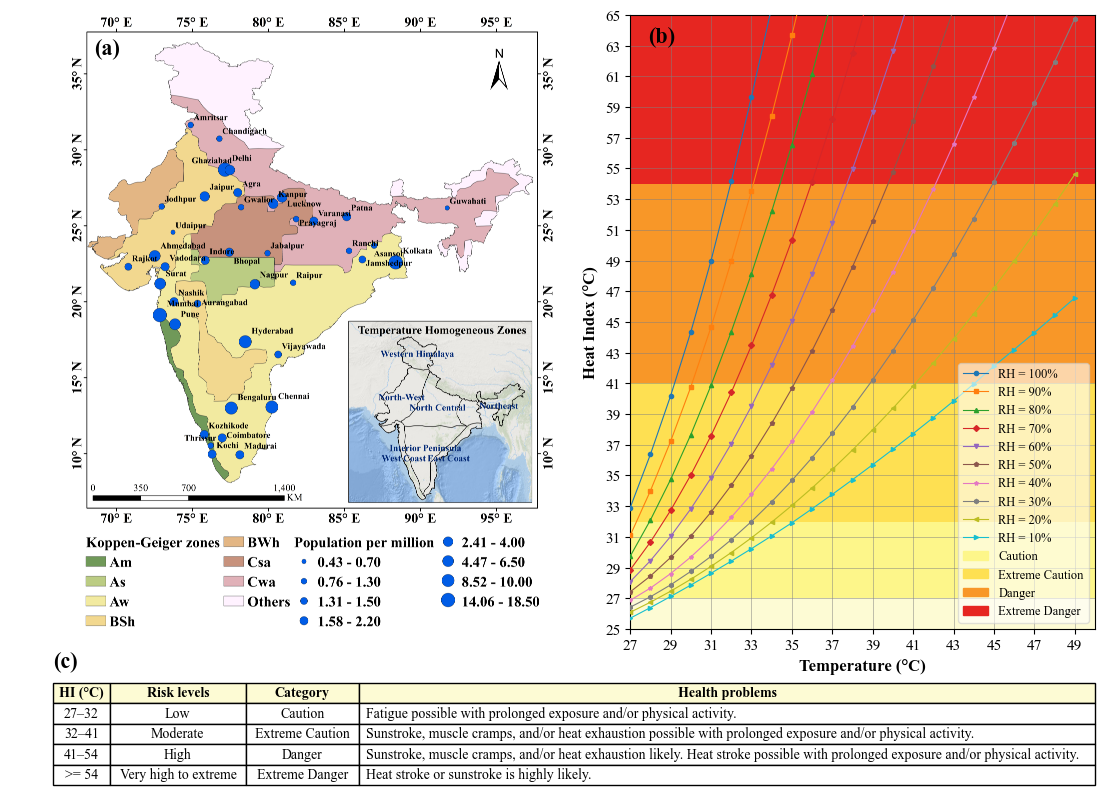

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import matplotlib.image as mpimg
import textwrap

# ==========================================
# --- CUSTOMIZATION VARIABLES ---
# ==========================================

# 1. Image Path Setup
# -------------------
image_path = r"C:\Users\PC1\Desktop\Code_Data\Data\Figure_1\Figure_1a.png" 

# 2. Figure & Layout Settings
# ---------------------------
fig_width = 14  # 16               
fig_height = 10   # 8                
plot_to_table_ratio = [6, 1]       


image_vs_chart_width_ratio = [1.3, 1.0] 

# 3. Chart Customizations (Subplot b)
# -----------------------------------
line_width = 0.8           
marker_size = 3            
x_tick_step = 2            
y_tick_step = 2            
x_label_weight = 'bold'   
y_label_weight = 'bold'   
marker_list = ['o', 's', '^', 'D', 'v', 'p', '*', 'h', '<', '>']

# NEW: Chart Font Size Customizations
chart_label_fontsize = 12  
chart_tick_fontsize = 11   
chart_legend_fontsize = 9  

# 4. Table Customizations (Subplot c)
# -----------------------------------
table_shift_right = 0.04   

table_font_size = 10
table_header_bg_color = '#FDFBD4' 
table_cell_bg_color = '#FFFFFF'    

# -- SPACING & PADDING CONTROL --
table_col_widths = [0.05, 0.12, 0.10, 0.65] 
text_wrap_width = 200              
table_row_height_scale = 1.6      


table_cell_padding = 0.01          
# ==========================================

# Set font to Times New Roman for all text elements globally
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12        

# Heat Index computation using the standard NOAA regression equation
def calc_heat_index(T_C_array, RH):
    """Calculates Heat Index using the standard NOAA regression equation."""
    T_F = T_C_array * 9.0 / 5.0 + 32.0
    
    HI_F = -42.379 + 2.04901523 * T_F + 10.14333127 * RH \
           - 0.22475541 * T_F * RH - 0.00683783 * (T_F**2) \
           - 0.05481717 * (RH**2) + 0.00122874 * (T_F**2) * RH \
           + 0.00085282 * T_F * (RH**2) - 0.00000199 * (T_F**2) * (RH**2)
    
    HI_F_adj = np.copy(HI_F)
    for i in range(len(T_F)):
        if RH < 13 and 80 <= T_F[i] <= 112:
            HI_F_adj[i] -= ((13 - RH) / 4.0) * np.sqrt((17 - np.abs(T_F[i] - 95.0)) / 17.0)
        elif RH > 85 and 80 <= T_F[i] <= 87:
            HI_F_adj[i] += ((RH - 85) / 10.0) * ((87 - T_F[i]) / 5.0)
            
    return (HI_F_adj - 32.0) * 5.0 / 9.0

# ------------------------------------------
# LAYOUT SETUP (GridSpec: 2 Rows, 2 Columns)
# ------------------------------------------
fig = plt.figure(figsize=(fig_width, fig_height))

# Applying the custom image_vs_chart_width_ratio here
gs = gridspec.GridSpec(2, 2, height_ratios=plot_to_table_ratio, 
                       width_ratios=image_vs_chart_width_ratio, 
                       wspace=0.03, hspace=0.15)

ax_img = fig.add_subplot(gs[0, 0])      # Top Left
ax_plot = fig.add_subplot(gs[0, 1])     # Top Right
ax_table = fig.add_subplot(gs[1, :])    # Bottom Row spanning both columns

# ==========================================
# --- (a) IMAGE GENERATION (Top Left Axes) ---
# ==========================================
try:
    img = mpimg.imread(image_path)
    ax_img.imshow(img)
    ax_img.axis('off')
except FileNotFoundError:
    ax_img.text(0.5, 0.5, f"Image '{image_path}' not found.\nPlease check the path.", 
                ha='center', va='center', fontsize=12, color='red')
    ax_img.axis('off')

# Add subplot label (a)
ax_img.text(0.05, 0.96, '(a)', transform=ax_img.transAxes, fontsize=16, fontweight='bold', va='top')

# ==========================================
# --- (b) PLOT GENERATION (Top Right Axes) ---
# ==========================================
no_color = '#FDFBD4'
caution_color = '#FDF68A'
ext_caution_color = '#FEE052'
danger_color = '#F89728'
ext_danger_color = '#E62621'

# Background color bands
ax_plot.axhspan(25, 27, facecolor=no_color, zorder=1)
ax_plot.axhspan(27, 32, facecolor=caution_color, zorder=1)
ax_plot.axhspan(32, 41, facecolor=ext_caution_color, zorder=1)
ax_plot.axhspan(41, 54, facecolor=danger_color, zorder=1)
ax_plot.axhspan(54, 65, facecolor=ext_danger_color, zorder=1)

T_C = np.arange(27, 50, 1)
rhs = [100, 90, 80, 70, 60, 50, 40, 30, 20, 10]
lines = []

for i, rh in enumerate(rhs):
    HI_C = calc_heat_index(T_C, rh)
    current_marker = marker_list[i % len(marker_list)]
    
    # Applied user configuration for line_width and marker_size here
    line, = ax_plot.plot(T_C, HI_C, linestyle='-', marker=current_marker, 
                         linewidth=line_width, markersize=marker_size, 
                         label=f'RH = {rh}%', zorder=3)
    lines.append(line)

# Applied custom font sizes for labels and ticks
ax_plot.set_xlabel('Temperature (°C)', fontweight=x_label_weight, fontsize=chart_label_fontsize)
ax_plot.set_ylabel('Heat Index (°C)', fontweight=y_label_weight, fontsize=chart_label_fontsize)
ax_plot.tick_params(axis='both', which='major', labelsize=chart_tick_fontsize)

ax_plot.set_xlim(27, 50)
ax_plot.set_ylim(25, 65)

ax_plot.set_xticks(np.arange(27, 51, x_tick_step))
ax_plot.set_yticks(np.arange(25, 66, y_tick_step))

ax_plot.grid(True, which='both', linestyle='-', linewidth=0.5, color='gray', alpha=0.7, zorder=2)

caution_patch = mpatches.Patch(color=caution_color, label='Caution')
ext_caution_patch = mpatches.Patch(color=ext_caution_color, label='Extreme Caution')
danger_patch = mpatches.Patch(color=danger_color, label='Danger')
ext_danger_patch = mpatches.Patch(color=ext_danger_color, label='Extreme Danger')

handles = lines + [caution_patch, ext_caution_patch, danger_patch, ext_danger_patch]
# Applied custom font size for legend
ax_plot.legend(handles=handles, fontsize=chart_legend_fontsize, loc='lower right', framealpha=0.6)

# Add subplot label (b)
ax_plot.text(0.038, 0.98, '(b)', transform=ax_plot.transAxes, fontsize=16, fontweight='bold', va='top')

# ==========================================
# --- (c) TABLE GENERATION (Bottom Axes) ---
# ==========================================
ax_table.axis('off') # Hide axes for the table subplot

col_labels = ['HI (°C)', 'Risk levels', 'Category', 'Health problems']
table_data = [
    ['27–32', 'Low', 'Caution', 
     'Fatigue possible with prolonged exposure and/or physical activity.'],
    ['32–41', 'Moderate', 'Extreme Caution', 
     'Sunstroke, muscle cramps, and/or heat exhaustion possible with prolonged exposure and/or physical activity.'],
    ['41–54', 'High', 'Danger', 
     'Sunstroke, muscle cramps, and/or heat exhaustion likely. Heat stroke possible with prolonged exposure and/or physical activity.'],
    ['>= 54', 'Very high to extreme', 'Extreme Danger', 
     'Heat stroke or sunstroke is highly likely.']
]

# Apply text wrapping
for row in table_data:
    row[3] = textwrap.fill(row[3], width=text_wrap_width)

# Calculate dynamic bounding box to physically shift table to the right
table_bbox = [table_shift_right, 0.0, 1.0 - table_shift_right, 1.0]

# Create the table using the bbox for custom placement
table = ax_table.table(
    cellText=table_data, 
    colLabels=col_labels, 
    cellLoc='left', 
    colWidths=table_col_widths,
    bbox=table_bbox
)

# Apply table customizations (Fonts, Scaling, Header Colors)
table.auto_set_font_size(False)
table.set_fontsize(table_font_size)
table.scale(1, table_row_height_scale)

# Style the headers and cells
for (row_idx, col_idx), cell in table.get_celld().items():
    
    # Overwrite the default heavy padding to reduce space within cells
    cell.PAD = table_cell_padding 
    
    # Style Header Row
    if row_idx == 0:
        cell.set_text_props(weight='bold', family='Times New Roman')
        cell.set_facecolor(table_header_bg_color)
    # Style Data Rows
    else:
        cell.set_text_props(family='Times New Roman')
        cell.set_facecolor(table_cell_bg_color)
        
    # Center align the first 3 columns, keep left align for the 'Health Problems' column
    if col_idx < 3:
        cell.set_text_props(ha='center')

# Add subplot label (c)
ax_table.text(0.04, 1.3, '(c)', transform=ax_table.transAxes, fontsize=16, fontweight='bold', va='top')

# ==========================================
# --- OUTPUT & SAVE ---
# ==========================================
# Output directory setup
output_folder = r"C:\Users\PC1\Desktop\Code_Data\Data\Figure_1\output" 
os.makedirs(output_folder, exist_ok=True) 

file_path_png = os.path.join(output_folder, 'Figure_1.png')

plt.savefig(file_path_png, dpi=1200, bbox_inches='tight')

print(f"Plot successfully saved to:\n  - {file_path_png}")